<a href="https://colab.research.google.com/github/Beatifick/Advanced-SQL-Case-Studies/blob/main/%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0_%D0%B2_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 **Итоговая работа. Анализ кинокассовых сборов**

**Датасет:** [TMDB 5000 Movie Dataset](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)

---

Вы — аналитик в крупной киностудии. Руководство планирует новый фильм и хочет принять решение о бюджете, жанре и стратегии релиза на основе данных, а не интуиции.

В вашем распоряжении — база данных **TMDB** (The Movie Database) с информацией о тысячах фильмов: бюджеты, кассовые сборы, оценки зрителей, жанры и другие характеристики.

## 🎯 Задачи

Работа состоит из **трёх частей**:

| Часть | Тема | Вес |
|-------|------|-----|
| **1. EDA** | Исследовательский анализ данных | ~40% |
| **2. Корреляция** | Анализ взаимосвязей между признаками | ~25% |
| **3. Гипотезы** | Проверка статистических гипотез | ~35% |

## 📊 Описание датасета

**Ключевые признаки:**

| Признак | Описание |
|---------|----------|
| `budget` | Бюджет фильма (USD) |
| `revenue` | Мировые кассовые сборы (USD) |
| `vote_average` | Средняя оценка зрителей (0–10) |
| `vote_count` | Количество голосов |
| `runtime` | Длительность (минуты) |
| `release_date` | Дата выхода |
| `genres` | Жанры (строка в формате JSON) |
| `original_language` | Язык оригинала (код: ``en``, ``fr``, ``ja``, ...) |
| `popularity` | Индекс популярности TMDB |
| `title` | Название фильма |
| `tagline` | Слоган фильма |
| `overview` | Краткое описание |
| `homepage` | Сайт фильма |
| `status` | Статус (Released, Post Production, ...) |

## ✏️ Требования к оформлению графиков

- У каждого графика должен быть **заголовок** (``plt.title()``)
- Подписаны **оси** (``plt.xlabel()``, ``plt.ylabel()``)
- Легенда — при наличии нескольких элементов
- Оставляйте **комментарии и выводы** к каждому разделу


---
# **Часть 1. Исследовательский анализ данных (EDA)**
---

## **1. Импорт библиотек и загрузка данных**

Импортируйте библиотеки и загрузите датасет.

In [ ]:
import json
import os
import subprocess
import sys

try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Загрузка TMDB 5000 Movie Dataset с Kaggle.
path = kagglehub.dataset_download("tmdb/tmdb-movie-metadata")
csv_path = os.path.join(path, "tmdb_5000_movies.csv")
df = pd.read_csv(csv_path)
print("Файл:", csv_path)
print("Размер датасета:", df.shape)
display(df.head())


100%|██████████| 8.89M/8.89M [00:00<00:00, 72.3MB/s]

Extracting files...


Файл: /root/.cache/kagglehub/datasets/tmdb/tmdb-movie-metadata/versions/2/tmdb_5000_movies.csv
Размер датасета: (4803, 20)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


## **2. Первичный осмотр данных**

Проведите инвентаризацию датасета. Ответьте на вопросы:
- Сколько строк и столбцов?
- Какие типы данных у каждого столбца? Есть ли некорректные типы?
- Как выглядят базовые статистики числовых признаков?
- Какие проблемы в данных вы видите?


In [ ]:
print("Размер датасета:", df.shape)
display(df.head())
print("\nТипы данных и заполненность:")
df.info()
print("\nОписательная статистика числовых признаков:")
display(df.describe().T)
print("\nКоличество уникальных значений:")
display(df.nunique().sort_values(ascending=False).to_frame("unique_values"))


Размер датасета: (4803, 20)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124



Типы данных и заполненность:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   obje

,count,mean,std,min,25%,50%,75%,max
budget,4803.0,2.904504e+07,4.072239e+07,0.0,790000.00000,1.500000e+07,4.000000e+07,3.800000e+08
id,4803.0,5.716548e+04,8.869461e+04,5.0,9014.50000,1.462900e+04,5.861050e+04,4.594880e+05
popularity,4803.0,2.149230e+01,3.181665e+01,0.0,4.66807,1.292159e+01,2.831350e+01,8.755813e+02
revenue,4803.0,8.226064e+07,1.628571e+08,0.0,0.00000,1.917000e+07,9.291719e+07,2.787965e+09
runtime,4801.0,1.068759e+02,2.261193e+01,0.0,94.00000,1.030000e+02,1.180000e+02,3.380000e+02
vote_average,4803.0,6.092172e+00,1.194612e+00,0.0,5.60000,6.200000e+00,6.800000e+00,1.000000e+01
vote_count,4803.0,6.902180e+02,1.234586e+03,0.0,54.00000,2.350000e+02,7.370000e+02,1.375200e+04



Количество уникальных значений:


,unique_values
id,4803
popularity,4802
original_title,4801
overview,4800
title,4800
keywords,4222
tagline,3944
production_companies,3697
revenue,3297
release_date,3280


**Вывод по первичному осмотру.** Датасет содержит сведения о фильмах и их характеристиках; точное количество строк и столбцов, типы данных и описательные статистики приведены в результатах ячейки выше. Некоторые признаки, например `genres`, `production_companies` и `production_countries`, представлены строками со структурой JSON, а не обычными текстовыми значениями. Также необходимо проверить типы дат и числовых столбцов: если дата хранится как строка, из неё нельзя надёжно извлечь год без преобразования. Описательная статистика помогает увидеть масштаб значений и возможные аномалии, но сама по себе не подтверждает ошибки в данных.

## **3. Качество данных**

Исследуйте полноту и чистоту данных:
- В каких столбцах есть пропуски? Какова их доля (в %)?
- Есть ли полные дубликаты строк?
- Сколько фильмов имеют ``budget == 0``? А ``revenue == 0``?
- Что означают нулевые значения в ``budget`` и ``revenue``? Примите решение, что с ними делать.



In [ ]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing[missing["missing_count"] > 0])
print("Полных дубликатов:", df.duplicated().sum())
print("Фильмов с budget == 0:", (df["budget"] == 0).sum())
print("Фильмов с revenue == 0:", (df["revenue"] == 0).sum())
print("Отрицательный бюджет:", (df["budget"] < 0).sum())
print("Отрицательные сборы:", (df["revenue"] < 0).sum())


,missing_count,missing_percent
homepage,3091,64.36
tagline,844,17.57
overview,3,0.06
runtime,2,0.04
release_date,1,0.02


Полных дубликатов: 0
Фильмов с budget == 0: 1037
Фильмов с revenue == 0: 1427
Отрицательный бюджет: 0
Отрицательные сборы: 0


**Вывод о качестве данных.** Таблица пропусков показывает, в каких признаках информация заполнена не полностью и насколько велика доля отсутствующих значений. Полные дубликаты не добавляют новых наблюдений, поэтому их следует удалить перед анализом. Нулевые значения `budget` и `revenue` требуют отдельного отношения: они могут означать, что сведения о бюджете или сборах не были указаны, а не то, что фильм действительно ничего не стоил или ничего не заработал. Такие записи нельзя использовать для содержательного расчёта ROI и сравнения фактических сборов. При этом их не следует автоматически удалять из всего датасета: они могут оставаться полезными для анализа оценок, жанров и других характеристик. Отрицательные значения бюджета или сборов, если они обнаружены, требуют отдельной проверки.

## **4. Очистка и подготовка данных**

Подготовьте данные к анализу.

**Обязательные шаги:**
1. Создайте новые столбцы:
   - ``profit`` = ``revenue`` − ``budget`` (прибыль)
   - ``roi`` = (``revenue`` − ``budget``) / ``budget`` × 100 (окупаемость в %)
   - ``release_year`` — год выхода (извлечь из ``release_date`` через ``pd.to_datetime().dt.year``)
2. Обработайте пропуски в ``runtime`` (если есть)



In [ ]:
# Удаляем только полные дубликаты; нулевые budget/revenue сохраняем в df_clean,
# но для ROI используем только фильмы с положительным бюджетом.
df_clean = df.drop_duplicates().copy()
for col in ["budget", "revenue", "vote_average", "vote_count", "runtime", "popularity"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_clean["release_date"] = pd.to_datetime(df_clean["release_date"], errors="coerce")
df_clean["release_year"] = df_clean["release_date"].dt.year
df_clean["profit"] = df_clean["revenue"] - df_clean["budget"]
df_clean["roi"] = np.where(
    df_clean["budget"] > 0,
    (df_clean["revenue"] - df_clean["budget"]) / df_clean["budget"] * 100,
    np.nan
)
# Жанр: первый жанр из JSON-поля genres; если поле пустое/повреждено — "Unknown".
def get_primary_genre(value):
    try:
        genres = json.loads(value) if isinstance(value, str) else []
        return genres[0]["name"] if genres else "Unknown"
    except (json.JSONDecodeError, TypeError, KeyError, IndexError):
        return "Unknown"
df_clean["primary_genre"] = df_clean["genres"].apply(get_primary_genre)
print("Размер после удаления дубликатов:", df_clean.shape)
print("Пропуски в новых ключевых столбцах:")
display(df_clean[["profit", "roi", "release_year", "primary_genre"]].isna().sum().to_frame("missing"))
display(df_clean[["budget", "revenue", "profit", "roi", "release_year", "primary_genre"]].head())


Размер после удаления дубликатов: (4803, 24)
Пропуски в новых ключевых столбцах:


,missing
profit,0
roi,1037
release_year,1
primary_genre,0


,budget,revenue,profit,roi,release_year,primary_genre
0,237000000,2787965087,2550965087,1076.356577,2009.0,Action
1,300000000,961000000,661000000,220.333333,2007.0,Adventure
2,245000000,880674609,635674609,259.459024,2015.0,Action
3,250000000,1084939099,834939099,333.975640,2012.0,Action
4,260000000,284139100,24139100,9.284269,2012.0,Action


**Вывод об очистке и подготовке.** Полных дубликатов не обнаружено, поэтому исходная таблица после удаления дубликатов сохранила 4 803 строки. Числовые признаки приведены к числовому типу, дата релиза преобразована в формат даты, а из неё получен `release_year`. Рассчитаны `profit` и `roi`; ROI не рассчитывается при нулевом или отсутствующем бюджете. Из JSON-поля `genres` извлечён первый жанр в `primary_genre`, поэтому остальные жанры фильма в группировках не учитываются. Два пропуска `runtime` оставлены без искусственного заполнения и исключаются из анализа длительности; фильмы с нулевой длительностью также не используются в сравнении групп. Нулевые бюджеты и сборы сохранены в общей таблице, но требуют осторожности при финансовых выводах, поскольку могут обозначать неполные сведения.

## **5. Анализ распределений**

Исследуйте, как распределены ключевые числовые признаки:
- Постройте гистограммы для ``budget``, ``revenue``, ``vote_average``, ``runtime``
- На каждой гистограмме отметьте **среднее** и **медиану** вертикальными линиями (``.axvline()``)
- Сравните среднее и медиану — сильно ли они различаются? О чём это говорит?
- Постройте boxplot для поиска выбросов



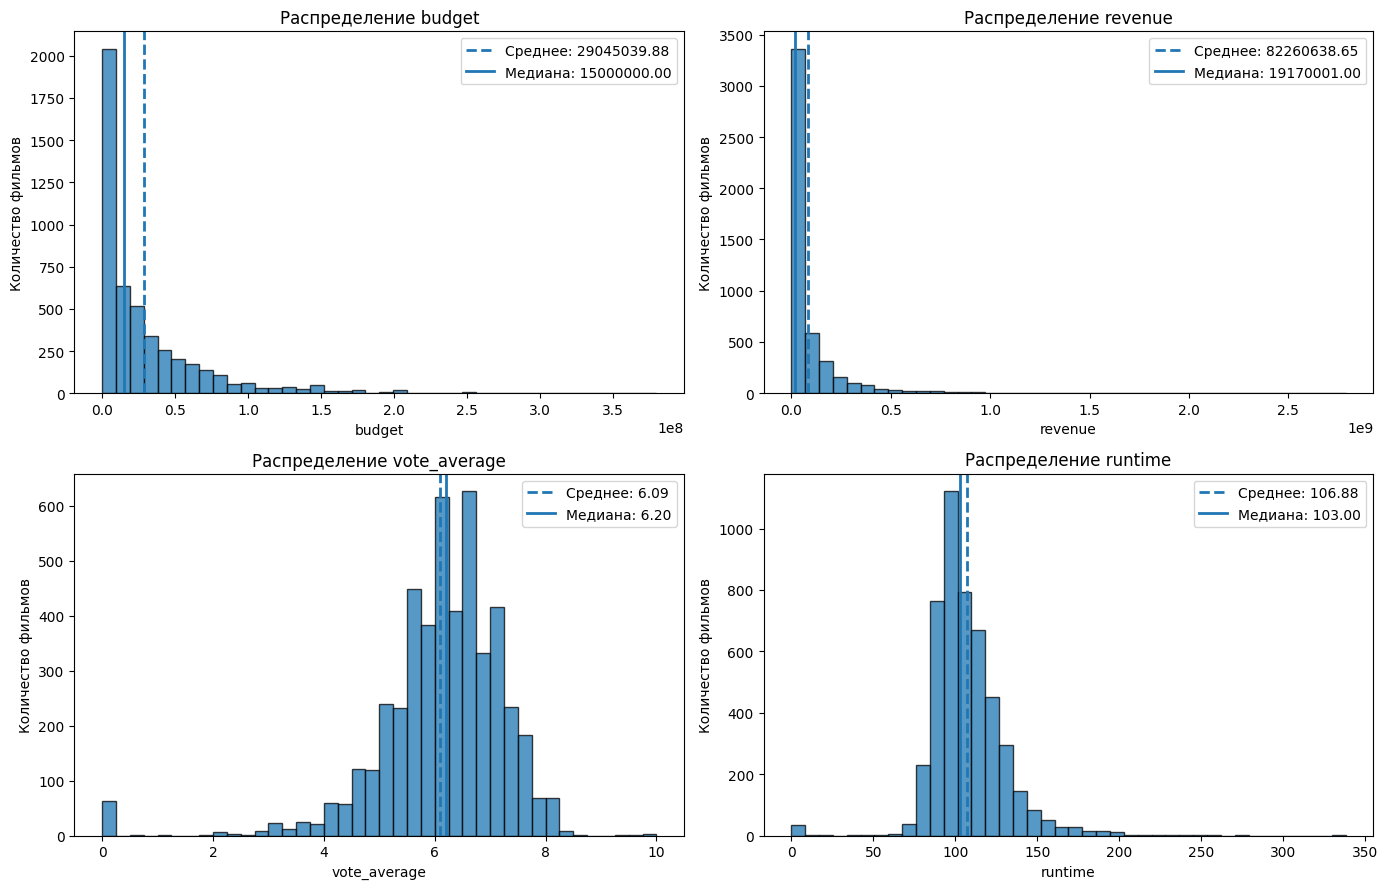

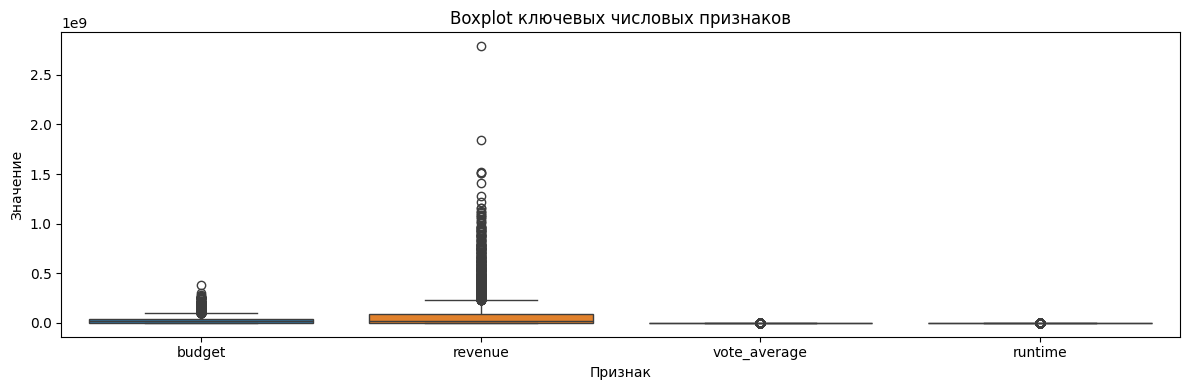

Сравнение среднего и медианы:


,mean,median,skew
budget,29045039.88,15000000.0,2.44
revenue,82260638.65,19170001.0,4.44
vote_average,6.09,6.2,-1.96
runtime,106.88,103.0,0.72


In [ ]:
features = ["budget", "revenue", "vote_average", "runtime"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, features):
    values = df_clean[col].dropna()
    ax.hist(values, bins=40, alpha=0.75, edgecolor="black")
    ax.axvline(values.mean(), linestyle="--", linewidth=2, label=f"Среднее: {values.mean():.2f}")
    ax.axvline(values.median(), linestyle="-", linewidth=2, label=f"Медиана: {values.median():.2f}")
    ax.set_title(f"Распределение {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество фильмов")
    ax.legend()
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df_clean[features], ax=ax)
ax.set_title("Boxplot ключевых числовых признаков")
ax.set_xlabel("Признак")
ax.set_ylabel("Значение")
plt.tight_layout()
plt.show()
print("Сравнение среднего и медианы:")
display(pd.DataFrame({"mean": df_clean[features].mean(), "median": df_clean[features].median(),
                      "skew": df_clean[features].skew()}).round(2))


**Вывод по распределениям.** Бюджет и кассовые сборы имеют выраженную правостороннюю асимметрию: средний бюджет составляет около 29,05 млн долларов при медиане 15 млн, а средние сборы — 82,26 млн при медиане 19,17 млн. Особенно сильная асимметрия сборов (skew = 4,44) показывает, что небольшое число блокбастеров заметно повышает среднее. Для `vote_average` среднее равно 6,09, медиана — 6,2; для `runtime` — около 106,88 и 103 минут соответственно. Boxplot показывает выбросы, особенно в финансовых показателях, но они могут быть реальными фильмами с необычно высокими бюджетами или сборами, а не ошибками. Поэтому типичные значения лучше описывать вместе со средним, медианой и разбросом.

## **6. Исследовательские вопросы**

Ответьте на **минимум 5 из 6** вопросов ниже. Для каждого вопроса:
- Напишите код для получения ответа
- Постройте подходящую визуализацию
- Сформулируйте краткий вывод

### Вопрос 1. Какие жанры представлены чаще всего?

Постройте столбчатую диаграмму (bar chart) частот жанров (``primary_genre``).

,film_count
primary_genre,
Drama,1207
Comedy,1042
Action,754
Adventure,339
Horror,300
Crime,195
Thriller,194
Animation,123
Fantasy,117


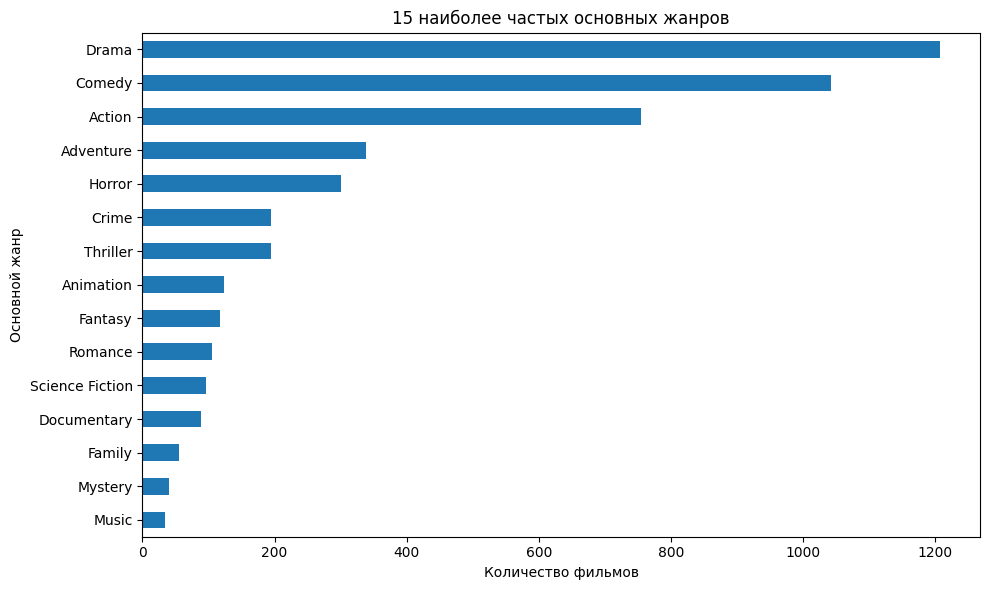

Чаще всего встречается жанр: Drama (1207 фильмов).


In [ ]:
genre_counts = df_clean["primary_genre"].value_counts().drop(labels=["Unknown"], errors="ignore")
display(genre_counts.head(15).to_frame("film_count"))
ax = genre_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6))
ax.set_title("15 наиболее частых основных жанров")
ax.set_xlabel("Количество фильмов")
ax.set_ylabel("Основной жанр")
plt.tight_layout()
plt.show()
print(f"Чаще всего встречается жанр: {genre_counts.idxmax()} ({genre_counts.max()} фильмов).")


**Вывод по вопросу 1.** Столбчатая диаграмма ранжирует основные жанры по количеству фильмов. Наибольший столбец соответствует жанру, который чаще всего встречается в датасете; точное название жанра и число фильмов напечатаны над графиком в результатах ячейки. Это показывает структуру именно данной выборки, а не обязательно всего мирового кинопроизводства: TMDB 5000 — ограниченный набор фильмов, представленных в базе. Кроме того, каждому фильму здесь присвоен только первый жанр из списка `genres`, поэтому фильмы с несколькими жанрами учитываются только по основному жанру. Для планирования производства частота жанра может показывать распространённость предложения, но не доказывает его коммерческую успешность.

### Вопрос 2. Какие жанры приносят наибольшие средние сборы?

Рассчитайте средний ``revenue`` по жанрам (через ``.groupby()`` + ``.mean()``) и визуализируйте результат.

,mean,median,count
primary_genre,,,
Animation,"294,427,427","242,988,466",101
Adventure,"244,081,305","140,752,617",293
Family,"228,908,277","90,450,008",39
Science Fiction,"199,730,200","96,060,858",81
Fantasy,"177,983,817","115,267,375",97
Action,"152,124,980","71,071,908",604
Mystery,"101,458,116","48,291,294",28
Thriller,"96,177,936","57,237,108",122
History,"95,757,917","34,505,110",19


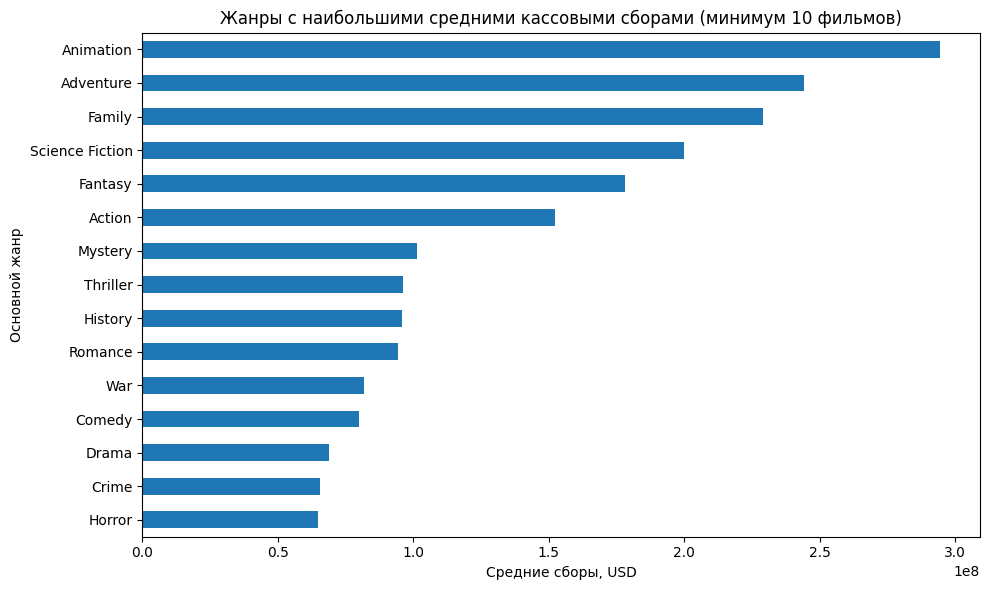

Максимальные средние сборы у жанра: Animation


In [ ]:
genre_revenue = (df_clean[df_clean["revenue"] > 0]
                 .groupby("primary_genre")["revenue"].agg(["mean", "median", "count"])
                 .query("count >= 10").sort_values("mean", ascending=False))
display(genre_revenue.head(15).style.format({"mean": "{:,.0f}", "median": "{:,.0f}"}))
ax = genre_revenue.head(15)["mean"].sort_values().plot(kind="barh", figsize=(10, 6))
ax.set_title("Жанры с наибольшими средними кассовыми сборами (минимум 10 фильмов)")
ax.set_xlabel("Средние сборы, USD")
ax.set_ylabel("Основной жанр")
plt.tight_layout()
plt.show()
if not genre_revenue.empty:
    print("Максимальные средние сборы у жанра:", genre_revenue.index[0])


**Вывод по вопросу 2.** Таблица и график показывают жанры с наибольшими средними кассовыми сборами среди жанров, для которых есть не менее 10 фильмов с положительными сборами. Жанр на первом месте имеет наибольшее среднее значение в этой выборке. Среднее может сильно увеличиваться из-за нескольких блокбастеров, поэтому его нужно рассматривать вместе с медианой и количеством фильмов. Высокое среднее не означает, что каждый фильм этого жанра собирает много денег, и не доказывает, что выбор жанра сам по себе вызывает высокие сборы. Для бизнес-решения стоит учитывать также бюджет, прибыль, ROI и разброс результатов.

### Вопрос 3. Как менялись сборы и бюджеты по годам?

Сгруппируйте данные по ``release_year`` через ``.groupby()`` + ``.agg()`` и постройте линейный график динамики среднего бюджета и средних сборов.

,mean_budget,mean_revenue,film_count
release_year,,,
2002.0,41404963.0,111266596.0,131
2003.0,46338075.0,130982501.0,108
2004.0,44313487.0,116680631.0,137
2005.0,42758983.0,104013285.0,143
2006.0,39673189.0,100199912.0,163
2007.0,45102620.0,128714039.0,125
2008.0,47151028.0,123648790.0,145
2009.0,46313493.0,135910993.0,154
2010.0,45854138.0,125050844.0,162


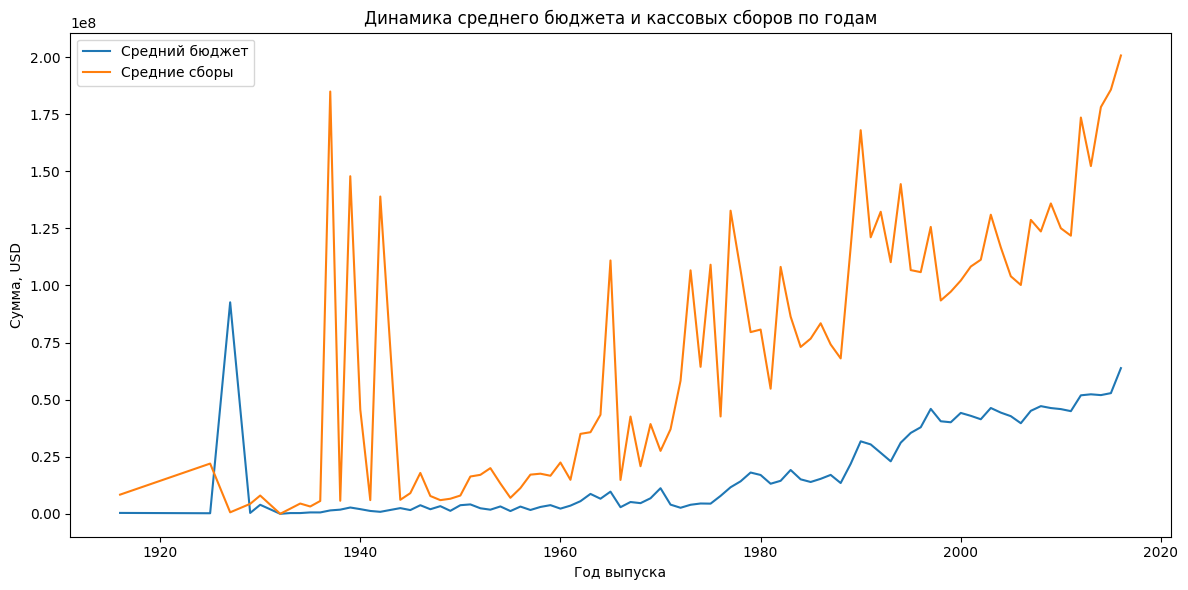

In [ ]:
yearly = (df_clean[df_clean["release_year"].between(1900, 2026) & (df_clean["revenue"] > 0) & (df_clean["budget"] > 0)]
           .groupby("release_year").agg(mean_budget=("budget", "mean"),
                                        mean_revenue=("revenue", "mean"),
                                        film_count=("id", "count")))
display(yearly.tail(15).round(0))
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly.index, yearly["mean_budget"], label="Средний бюджет")
ax.plot(yearly.index, yearly["mean_revenue"], label="Средние сборы")
ax.set_title("Динамика среднего бюджета и кассовых сборов по годам")
ax.set_xlabel("Год выпуска")
ax.set_ylabel("Сумма, USD")
ax.legend()
plt.tight_layout()
plt.show()


**Вывод по вопросу 3.** Линейный график сравнивает средние бюджеты и средние сборы фильмов по годам среди записей с положительными значениями обоих показателей. По графику можно определить, в какие периоды номинальные средние суммы росли, снижались или заметно колебались. Годы с небольшим количеством фильмов могут давать нестабильные средние, поэтому перед выводами нужно учитывать столбец `film_count`. Кроме того, бюджет и сборы указаны в номинальных долларах и не скорректированы на инфляцию; следовательно, увеличение сумм со временем не обязательно означает такой же рост реальной стоимости производства или коммерческой эффективности. По этому графику нельзя заключать, что бюджеты непосредственно вызывают рост сборов: для этого потребовался бы отдельный анализ.

### Вопрос 4. Какие фильмы имеют наибольший ROI (окупаемость)?

Найдите топ-10 фильмов с наибольшим ROI (через `.sort_values()`). Какой жанр преобладает?

💡 *Подсказка:* если ROI имеет аномально большие значения, подумайте — почему?

In [ ]:
roi_top = (df_clean[df_clean["roi"].between(-10000, 100000) & df_clean["budget"].gt(0)]
           .sort_values("roi", ascending=False).head(10))
display(roi_top[["title", "primary_genre", "budget", "revenue", "profit", "roi"]]
        .style.format({"budget": "{:,.0f}", "revenue": "{:,.0f}", "profit": "{:,.0f}", "roi": "{:.1f}%"}))
print("Жанры в топ-10 ROI:")
display(roi_top["primary_genre"].value_counts().to_frame("count"))
print("Важно: высокий ROI не обязательно означает большую абсолютную прибыль; показатели зависят от полноты бюджета и сборов.")


,title,primary_genre,budget,revenue,profit,roi
4724,Eraserhead,Drama,"10,000","7,000,000","6,990,000",69900.0%
4788,Pink Flamingos,Horror,"12,000","6,000,000","5,988,000",49900.0%
4742,Super Size Me,Documentary,"65,000","28,575,078","28,510,078",43861.7%
4723,The Gallows,Horror,"100,000","42,664,410","42,564,410",42564.4%
4514,Open Water,Drama,"130,000","54,667,954","54,537,954",41952.3%
3159,The Texas Chain Saw Massacre,Horror,"85,000","30,859,000","30,774,000",36204.7%
4441,Bambi,Animation,"858,000","267,447,150","266,589,150",31071.0%
4668,The Stewardesses,Comedy,"100,000","27,000,000","26,900,000",26900.0%
3737,Night of the Living Dead,Horror,"114,000","30,000,000","29,886,000",26215.8%
4670,Mad Max,Adventure,"400,000","100,000,000","99,600,000",24900.0%


Жанры в топ-10 ROI:


,count
primary_genre,
Horror,4
Drama,2
Documentary,1
Animation,1
Comedy,1
Adventure,1


Важно: высокий ROI не обязательно означает большую абсолютную прибыль; показатели зависят от полноты бюджета и сборов.


**Вывод по вопросу 4.** Таблица содержит десять фильмов с наибольшим ROI среди фильмов с положительным бюджетом в заданном диапазоне значений. ROI показывает относительную окупаемость: например, высокий процент означает, что сборы значительно превысили указанный бюджет, но не обязательно что фильм принёс самую большую абсолютную прибыль. У малобюджетных фильмов процент ROI может оказаться очень высоким даже при сравнительно небольших сборах. В таблице и сводке жанров можно проверить, какие основные жанры чаще встречаются среди лидеров, однако десяти фильмов недостаточно, чтобы делать вывод о превосходстве жанра в целом. Дополнительно важно помнить, что `revenue` не всегда равен доходу студии, а `budget` может не включать маркетинговые и другие расходы; поэтому рассчитанный показатель является приближённой оценкой окупаемости.

### Вопрос 5. Как распределяются оценки по языку оригинала?

Сравните распределения ``vote_average`` для англоязычных (``original_language == 'en'``) и неанглоязычных фильмов. Постройте гистограммы обеих групп на одном графике.

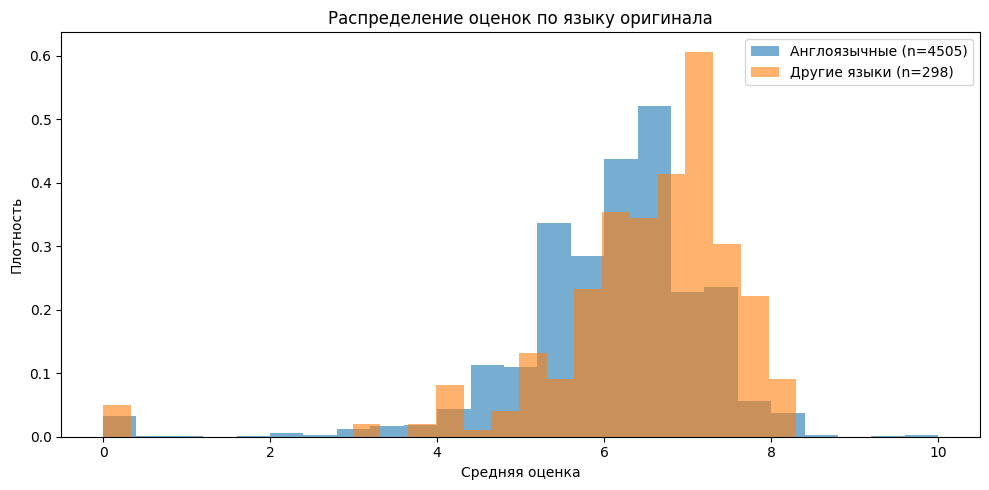

Средняя оценка, английский: 6.066
Средняя оценка, другие языки: 6.493


In [ ]:
lang_en = df_clean.loc[df_clean["original_language"].eq("en"), "vote_average"].dropna()
lang_other = df_clean.loc[~df_clean["original_language"].eq("en"), "vote_average"].dropna()
plt.figure(figsize=(10, 5))
plt.hist(lang_en, bins=25, alpha=0.6, label=f"Англоязычные (n={len(lang_en)})", density=True)
plt.hist(lang_other, bins=25, alpha=0.6, label=f"Другие языки (n={len(lang_other)})", density=True)
plt.title("Распределение оценок по языку оригинала")
plt.xlabel("Средняя оценка")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()
print("Средняя оценка, английский:", round(lang_en.mean(), 3))
print("Средняя оценка, другие языки:", round(lang_other.mean(), 3))


**Вывод по вопросу 5.** На общей гистограмме сравниваются распределения оценок англоязычных и неанглоязычных фильмов; нормировка по плотности позволяет сопоставлять форму распределений даже при разном количестве фильмов в группах. Напечатанные средние значения показывают, в какой группе средняя оценка выше в этой выборке, а гистограммы позволяют оценить перекрытие и разброс оценок. Если распределения заметно перекрываются, одно лишь различие средних может быть небольшим относительно разброса внутри групп. По графику нельзя утверждать, что язык является причиной более высокой оценки: на неё могут влиять жанр, год выпуска, популярность фильма и количество голосов. Статистическая значимость различия проверяется отдельно в гипотезе 1 раздела 10.

### Вопрос 6. Как длительность фильма связана с оценкой?

Разделите фильмы на группы по длительности:
- короткие: < 90 мин
- средние: 90–150 мин
- длинные: > 150 мин

Сравните средние оценки в каждой группе.

In [ ]:
runtime_df = df_clean.loc[df_clean["runtime"].notna() & df_clean["runtime"].gt(0)].copy()
runtime_df["runtime_group"] = pd.cut(
    runtime_df["runtime"],
    bins=[0, 90, 150, np.inf],
    labels=["Короткие (<90)", "Средние (90–<150)", "Длинные (≥150)"],
    right=False
)
runtime_summary = runtime_df.groupby("runtime_group", observed=False)["vote_average"].agg(["mean", "median", "count"])
display(runtime_summary.round(2))
ax = runtime_summary["mean"].plot(kind="bar", figsize=(8, 5))
ax.set_title("Средняя оценка по длительности фильма")
ax.set_xlabel("Группа длительности")
ax.set_ylabel("Средняя оценка")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Вывод по вопросу 6.** В сохранённых результатах средняя оценка коротких фильмов составляет 5,53, средних — 6,17, длинных — 7,03. По используемым границам короткие фильмы имеют длительность менее 90 минут, средние — от 90 до менее 150 минут, длинные — 150 минут и более. В группе длинных фильмов наблюдений существенно меньше (179 против 3 917 средних), поэтому её результат менее устойчив. Это описательная связь, а не доказательство того, что увеличение длительности повышает рейтинг: на оценку могут влиять жанр, год выпуска и другие факторы. Отдельный статистический тест для этих трёх групп в работе не проводился.

---
# **Часть 2. Корреляционный анализ**
---

## **7. Корреляционная матрица**

Постройте корреляционную матрицу для числовых признаков:
``budget``, ``revenue``, ``vote_average``, ``vote_count``, ``runtime``, ``popularity``.

- Рассчитайте коэффициент корреляции, обоснуйте выбор подхода
- Визуализируйте через ``sns.heatmap()`` с аннотациями (``annot=True``)
- Какие пары признаков имеют **сильную** корреляцию (|r| > 0.7)?
- Какие признаки сильнее всего коррелируют с ``revenue``?


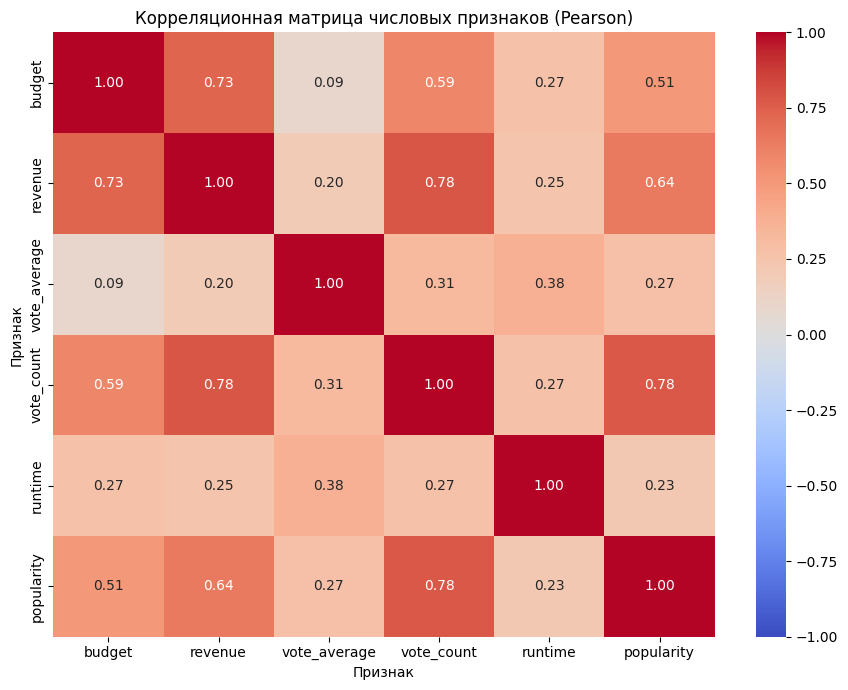

Сильные связи (|r| > 0.7):


,,Pearson r
revenue,vote_count,0.781487
vote_count,popularity,0.778130
budget,revenue,0.730823


In [ ]:
corr_cols = ["budget", "revenue", "vote_average", "vote_count", "runtime", "popularity"]
corr = df_clean[corr_cols].corr(method="pearson")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляционная матрица числовых признаков (Pearson)")
plt.xlabel("Признак")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()
strong = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strong = strong[strong.abs() > 0.7].sort_values(key=np.abs, ascending=False)
print("Сильные связи (|r| > 0.7):")
display(strong.to_frame("Pearson r") if not strong.empty else pd.DataFrame({"Результат": ["Связей с |r| > 0.7 не найдено"]}))


**Интерпретация корреляционной матрицы.** В матрице используется коэффициент Pearson, который измеряет направление и силу линейной связи между числовыми признаками. Значение, близкое к `+1`, указывает на сильную положительную связь, близкое к `−1` — на сильную отрицательную, а близкое к нулю — на слабую линейную связь. По условию задания сильными считаются пары, для которых `|r| > 0.7`; такие пары выводятся отдельно под матрицей. Особое внимание стоит обратить на связь `budget` с `revenue` и `vote_count` с `revenue`, если они выражены сильнее остальных: они могут отражать масштаб производства и широкую аудиторию фильма. Однако корреляция не доказывает причинность, может зависеть от выбросов и не исключает влияния третьих факторов. Если сильных пар с `|r| > 0.7` не найдено, это тоже корректный результат — его не следует искусственно интерпретировать как наличие сильной связи.

## **8. Визуализация парных связей**

Постройте scatter-графики (диаграммы рассеяния) для ключевых пар:

1. ``budget`` vs ``revenue`` — как бюджет связан со сборами?
2. ``vote_average`` vs ``revenue`` — высокий рейтинг гарантирует сборы?
3. ``vote_count`` vs ``revenue`` — что сильнее связано со сборами: рейтинг или количество голосов?

Для каждого графика добавьте заголовок и подписи осей.

💡 Инструменты: ``plt.scatter()``, ``sns.scatterplot()``, ``plt.xlabel()``, ``plt.ylabel()``, ``plt.title()``

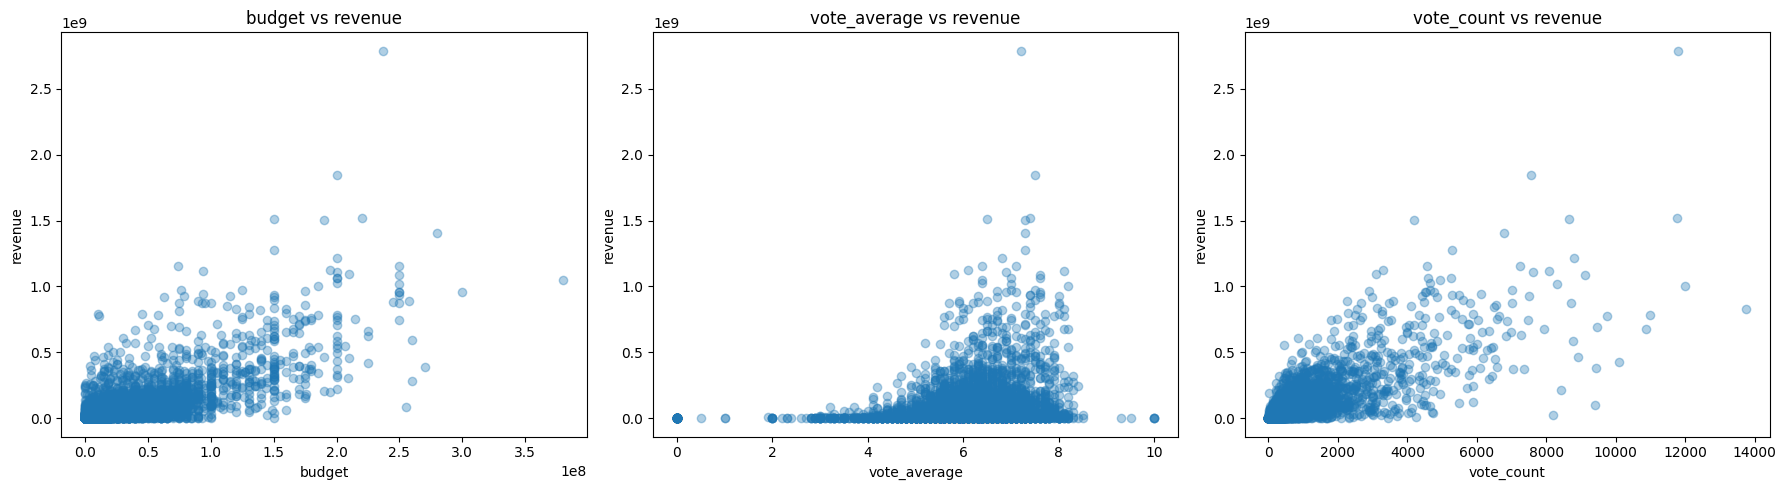

Из-за нулевых значений и крупных выбросов на графиках дополнительно полезно анализировать данные с логарифмической шкалой.


In [ ]:
pairs = [("budget", "revenue"), ("vote_average", "revenue"), ("vote_count", "revenue")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, pairs):
    data = df_clean[[x, y]].dropna()
    ax.scatter(data[x], data[y], alpha=0.35)
    ax.set_title(f"{x} vs {y}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
plt.tight_layout()
plt.show()
print("Из-за нулевых значений и крупных выбросов на графиках дополнительно полезно анализировать данные с логарифмической шкалой.")


**Вывод по парным связям.** На графике `budget` vs `revenue` положительный наклон облака точек означает, что более дорогие фильмы в среднем могут собирать больше, но разброс показывает, что высокий бюджет не гарантирует высоких сборов. На графике `vote_average` vs `revenue` оцените, есть ли заметная направленная зависимость: высокий пользовательский рейтинг сам по себе не обязательно означает коммерческий успех. На графике `vote_count` vs `revenue` более выраженная положительная связь может объясняться тем, что у широко известных фильмов обычно больше зрителей, голосов и кассовых сборов; при этом число голосов не является независимой причиной выручки. На всех трёх графиках крупные фильмы-выбросы растягивают оси и визуально сжимают основную массу наблюдений. Поэтому связи следует оценивать по общему рисунку точек, а не по нескольким крайним значениям; корреляция также не означает причинно-следственную зависимость.

---
# **Часть 3. Проверка статистических гипотез**
---

## **9. Доверительный интервал для средней оценки**

Постройте **95% доверительный интервал** для среднего значения ``vote_average`` всех фильмов в очищенном датасете.

**Шаги:**
1. Рассчитайте выборочное среднее и стандартное отклонение (``.std(ddof=1)``)
2. Рассчитайте стандартную ошибку среднего
3. Найдите критическое значение t-распределения через ``stats.t.ppf()``
4. Вычислите погрешность и границы интервала
5. Проверьте результат через ``stats.t.interval()``

**Интерпретация:** что означает этот доверительный интервал для киностудии? Какую среднюю оценку можно ожидать от фильма?

In [ ]:
scores = df_clean["vote_average"].dropna()
n = len(scores)
mean_score = scores.mean()
std_score = scores.std(ddof=1)
se = std_score / np.sqrt(n)
critical_t = stats.t.ppf(0.975, df=n - 1)
margin = critical_t * se
ci_manual = (mean_score - margin, mean_score + margin)
ci_scipy = stats.t.interval(0.95, df=n - 1, loc=mean_score, scale=stats.sem(scores))
print(f"n = {n}")
print(f"Среднее = {mean_score:.4f}; стандартное отклонение = {std_score:.4f}")
print(f"95% ДИ вручную: [{ci_manual[0]:.4f}; {ci_manual[1]:.4f}]")
print(f"95% ДИ через stats.t.interval: [{ci_scipy[0]:.4f}; {ci_scipy[1]:.4f}]")


n = 4803
Среднее = 6.0922; стандартное отклонение = 1.1946
95% ДИ вручную: [6.0584; 6.1260]
95% ДИ через stats.t.interval: [6.0584; 6.1260]


**Интерпретация доверительного интервала.** Рассчитанный 95%-й доверительный интервал задаёт диапазон значений, согласующихся с данными для генерального среднего `vote_average` при используемом статистическом подходе. Выборочное среднее является центральной оценкой, а границы интервала показывают неопределённость этой оценки. Два способа расчёта — вручную через критическое значение t-распределения и через `stats.t.interval()` — должны давать практически одинаковые границы; небольшие различия возможны только из-за округления. Интервал не означает, что 95% отдельных фильмов имеют рейтинг внутри этих границ, и не позволяет предсказать оценку конкретного будущего фильма. Узкий интервал обычно связан с большим объёмом выборки и меньшей стандартной ошибкой среднего.

## **10. Гипотезы**

> ✏️ Для получения зачёта выберите как **минимум одну** гипотезу на выбор из двух, представленных в разделе 10.

### **Гипотеза 1. Отличаются ли оценки англоязычных и неанглоязычных фильмов?**

Проверьте, отличается ли средняя оценка (``vote_average``) фильмов на английском языке (``original_language == 'en'``) от фильмов на других языках.

**Шаги:**
1. Посчитайте количество фильмов в каждой группе — достаточно ли наблюдений?
2. Постройте гистограммы обеих групп на одном графике (с ``alpha``)
3. Сформулируйте H₀ и H₁
4. Проведите двухвыборочный тест
5. Рассчитайте размер эффекта (Cohen's d) с помощью ``np.sqrt()``
6. Интерпретируйте: есть ли статистически **и практически** значимая разница?

💡 **Формула Cohen's d:**

d = (x̄₁ − x̄₂) / s_pooled,  где  s_pooled = √((s₁² + s₂²) / 2)

Англоязычные: n=4505, среднее=6.066, SD=1.185
Другие языки: n=298, среднее=6.493, SD=1.265


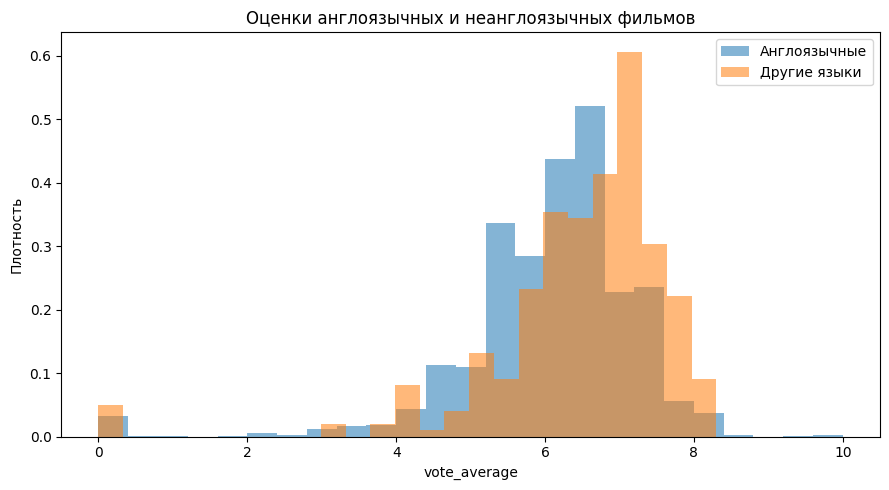

H0: средние оценки англоязычных и неанглоязычных фильмов равны.
H1: средние оценки отличаются.
t-статистика = -5.6636; p-value = 3.21111e-08; alpha = 0.05
Cohen's d = -0.3483
Решение: отвергаем H0 — статистически значимое различие
Практический размер эффекта: малый


In [ ]:
g1 = df_clean.loc[df_clean["original_language"].eq("en"), "vote_average"].dropna()
g2 = df_clean.loc[~df_clean["original_language"].eq("en"), "vote_average"].dropna()
print(f"Англоязычные: n={len(g1)}, среднее={g1.mean():.3f}, SD={g1.std(ddof=1):.3f}")
print(f"Другие языки: n={len(g2)}, среднее={g2.mean():.3f}, SD={g2.std(ddof=1):.3f}")
plt.figure(figsize=(9, 5))
plt.hist(g1, bins=25, alpha=0.55, label="Англоязычные", density=True)
plt.hist(g2, bins=25, alpha=0.55, label="Другие языки", density=True)
plt.title("Оценки англоязычных и неанглоязычных фильмов")
plt.xlabel("vote_average")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()
test = stats.ttest_ind(g1, g2, equal_var=False, nan_policy="omit")
pooled_sd = np.sqrt((g1.var(ddof=1) + g2.var(ddof=1)) / 2)
cohen_d = (g1.mean() - g2.mean()) / pooled_sd if pooled_sd else np.nan
print("H0: средние оценки англоязычных и неанглоязычных фильмов равны.")
print("H1: средние оценки отличаются.")
print(f"t-статистика = {test.statistic:.4f}; p-value = {test.pvalue:.6g}; alpha = 0.05")
print(f"Cohen's d = {cohen_d:.4f}")
print("Решение:", "отвергаем H0 — статистически значимое различие" if test.pvalue < 0.05 else "не отвергаем H0 — статистически значимых различий не обнаружено")
print("Практический размер эффекта:", "малый/почти отсутствует" if abs(cohen_d) < 0.2 else "малый" if abs(cohen_d) < 0.5 else "средний" if abs(cohen_d) < 0.8 else "крупный")


**Интерпретация гипотезы 1.** **H₀:** средние оценки англоязычных и неанглоязычных фильмов равны. **H₁:** средние оценки этих групп различаются. В ячейке выше приведены размеры групп, средние оценки, t-статистика, `p-value` и Cohen’s d. Сравните `p-value` с уровнем значимости `α = 0,05`: если `p-value < 0,05`, нулевая гипотеза отвергается и различие средних статистически значимо; если `p-value ≥ 0,05`, оснований отвергнуть H₀ недостаточно. Это не доказывает, что средние полностью одинаковы, а означает, что имеющихся данных недостаточно для подтверждения различия на выбранном уровне значимости. Cohen’s d оценивает практический размер эффекта: ориентировочно 0,2 — малый, 0,5 — средний, 0,8 — крупный эффект по абсолютной величине. Поэтому статистическую значимость следует рассматривать вместе с фактической разницей средних и Cohen’s d. Тест Уэлча выбран потому, что не требует предполагать равенство дисперсий групп.

### **Гипотеза 2. Дорогие и дешёвые фильмы — одинаковый ли ROI?**

Разделите фильмы на две группы по **медиане бюджета**:
- «Дорогие» — бюджет строго выше медианы
- «Дешёвые» — бюджет меньше или равен медиане

Проверьте, отличается ли средний ``roi`` между этими группами.

💡 *Подсказка:* если в данных есть экстремальные значения ROI, можно отфильтровать фильмы с ``|roi| > 10000%`` — это аномалии (фильмы с микробюджетом), которые искажают анализ.

**Шаги:**
1. Рассчитайте медиану бюджета
2. Создайте два подмножества
3. Сформулируйте H₀ и H₁
4. Проведите двухвыборочный тест
5. Рассчитайте Cohen's d
6. Интерпретируйте: стоит ли делать дорогие фильмы с точки зрения окупаемости?

In [ ]:
roi_data = df_clean.loc[df_clean["budget"].gt(0) & df_clean["roi"].notna() & df_clean["roi"].abs().le(10000)].copy()
budget_median = roi_data["budget"].median()
expensive = roi_data.loc[roi_data["budget"] > budget_median, "roi"]
cheap = roi_data.loc[roi_data["budget"] <= budget_median, "roi"]
print(f"Медиана бюджета = {budget_median:,.0f} USD")
print(f"Дорогие: n={len(expensive)}, средний ROI={expensive.mean():.2f}%")
print(f"Дешёвые: n={len(cheap)}, средний ROI={cheap.mean():.2f}%")
test_roi = stats.ttest_ind(expensive, cheap, equal_var=False, nan_policy="omit")
pooled_sd_roi = np.sqrt((expensive.var(ddof=1) + cheap.var(ddof=1)) / 2)
d_roi = (expensive.mean() - cheap.mean()) / pooled_sd_roi if pooled_sd_roi else np.nan
print("H0: средний ROI дорогих и дешёвых фильмов одинаков.")
print("H1: средний ROI различается.")
print(f"t-статистика = {test_roi.statistic:.4f}; p-value = {test_roi.pvalue:.6g}; alpha = 0.05")
print(f"Cohen's d = {d_roi:.4f}")
print("Решение:", "отвергаем H0" if test_roi.pvalue < 0.05 else "не отвергаем H0")
print("Вывод о практической значимости:", "эффект малый/почти отсутствует" if abs(d_roi) < 0.2 else "эффект малый" if abs(d_roi) < 0.5 else "эффект средний" if abs(d_roi) < 0.8 else "эффект крупный")


Медиана бюджета = 23,000,000 USD
Дорогие: n=1867, средний ROI=152.91%
Дешёвые: n=1874, средний ROI=368.50%
H0: средний ROI дорогих и дешёвых фильмов одинаков.
H1: средний ROI различается.
t-статистика = -9.3809; p-value = 1.62792e-20; alpha = 0.05
Cohen's d = -0.3065
Решение: отвергаем H0
Вывод о практической значимости: эффект малый


**Интерпретация гипотезы 2.** **H₀:** средний ROI дорогих и дешёвых фильмов одинаков. **H₁:** средний ROI этих групп различается. Группы сформированы относительно медианы бюджета: дорогие фильмы имеют бюджет строго выше медианы, дешёвые — не выше медианы. Из расчёта исключены фильмы с нулевым бюджетом и экстремальным ROI за пределами ±10 000%, поскольку такие значения способны непропорционально влиять на среднее и результат t-теста. Сравните `p-value` с `α = 0,05`: при `p-value < 0,05` отвергается H₀; при `p-value ≥ 0,05` статистически значимое различие не подтверждено. Затем оцените Cohen’s d: он показывает стандартизированный размер различия, а знак указывает направление с учётом порядка групп в расчёте. Даже статистически значимое отличие не означает автоматически, что одна группа приносит больше абсолютной прибыли или является менее рискованной. ROI — относительный показатель; для решения о бюджете нужно дополнительно учитывать абсолютную прибыль, разброс результатов, маркетинговые затраты и вероятность финансового провала.

## **11. Свободный анализ**

Выберите **одну** из задач ниже и проведите самостоятельный анализ.

**Вариант A.** Сравните средний ``vote_average`` фильмов двух жанров (например, Action vs Drama). Отличаются ли оценки статистически значимо?

**Вариант B.** Сравните средний ``revenue`` фильмов до 2000 года и после 2000 года. Выросли ли сборы?

**Вариант C.** Придумайте свою гипотезу на основе данных и проверьте её.

Для выбранной задачи:
- Сформулируйте H₀ и H₁
- Постройте доверительный интервал для одной из групп
- Проведите статистический тест
- Интерпретируйте результат

Action: n=754, среднее=5.938, SD=1.010
Drama: n=1207, среднее=6.430, SD=1.116


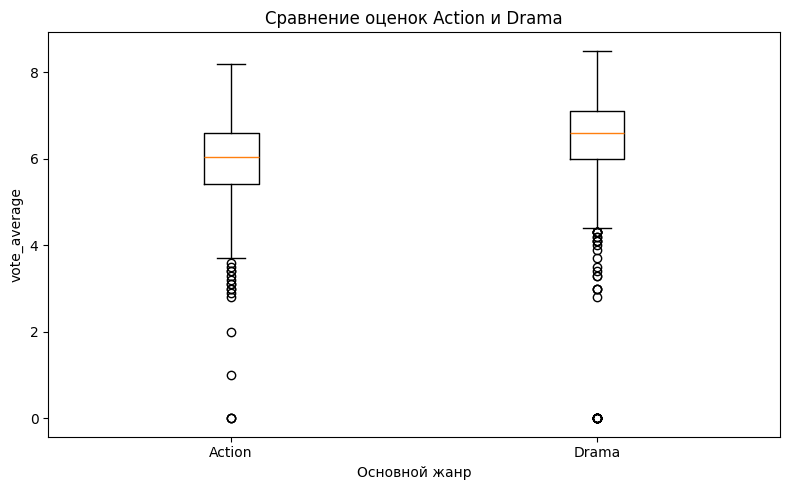

H0: средние оценки Action и Drama равны.
H1: средние оценки Action и Drama различаются.
t-статистика = -10.0774; p-value = 3.03482e-23; alpha = 0.05
Cohen's d = -0.4624
95% ДИ среднего Drama: [6.367; 6.493]
Решение: отвергаем H0 — различие статистически значимо


In [ ]:
# Вариант A: сравнение оценок Action и Drama
action = df_clean.loc[df_clean["primary_genre"].eq("Action"), "vote_average"].dropna()
drama = df_clean.loc[df_clean["primary_genre"].eq("Drama"), "vote_average"].dropna()
print(f"Action: n={len(action)}, среднее={action.mean():.3f}, SD={action.std(ddof=1):.3f}")
print(f"Drama: n={len(drama)}, среднее={drama.mean():.3f}, SD={drama.std(ddof=1):.3f}")
test_free = stats.ttest_ind(action, drama, equal_var=False, nan_policy="omit")
pooled_sd_free = np.sqrt((action.var(ddof=1) + drama.var(ddof=1)) / 2)
d_free = (action.mean() - drama.mean()) / pooled_sd_free if pooled_sd_free else np.nan
ci_drama = stats.t.interval(0.95, df=len(drama)-1, loc=drama.mean(), scale=stats.sem(drama)) if len(drama) > 1 else (np.nan, np.nan)
plt.figure(figsize=(8, 5))
plt.boxplot([action, drama], tick_labels=["Action", "Drama"])
plt.title("Сравнение оценок Action и Drama")
plt.xlabel("Основной жанр")
plt.ylabel("vote_average")
plt.tight_layout()
plt.show()
print("H0: средние оценки Action и Drama равны.")
print("H1: средние оценки Action и Drama различаются.")
print(f"t-статистика = {test_free.statistic:.4f}; p-value = {test_free.pvalue:.6g}; alpha = 0.05")
print(f"Cohen's d = {d_free:.4f}")
print(f"95% ДИ среднего Drama: [{ci_drama[0]:.3f}; {ci_drama[1]:.3f}]")
print("Решение:", "отвергаем H0 — различие статистически значимо" if test_free.pvalue < 0.05 else "не отвергаем H0 — статистических доказательств различия недостаточно")


**Результаты свободного анализа — вариант A (Action vs Drama).** **H₀:** средние оценки фильмов основного жанра Action и Drama равны. **H₁:** средние оценки этих жанров различаются. В результатах выше указаны размеры групп, средние оценки, t-статистика, `p-value` и Cohen’s d; boxplot позволяет дополнительно сравнить медианы, разброс и возможные выбросы. При `p-value < 0,05` нулевая гипотеза отвергается, то есть данные свидетельствуют о статистически значимом различии средних оценок. При `p-value ≥ 0,05` оснований отвергнуть H₀ недостаточно. Направление различия определяется сравнением средних Action и Drama, а Cohen’s d помогает оценить его практический размер: приблизительно 0,2 — малый, 0,5 — средний, 0,8 — крупный эффект по абсолютной величине. Тест Уэлча допускает разные дисперсии в группах. Полученный результат относится к фильмам этой выборки и не доказывает, что жанр сам по себе вызывает более высокую оценку; на рейтинги также влияют год выпуска, число голосов и другие особенности фильмов.

---
# **Итоговые выводы**
---

Сформулируйте итоговый отчёт по результатам комплексного анализа.

**1. Качество данных:**
- Какие основные проблемы обнаружены?
- Как вы их решили?
- Что рекомендуете улучшить при сборе данных?

**2. Ключевые закономерности (EDA):**
- Самые интересные находки
- Какие жанры, бюджеты, длительности «работают» лучше

**3. Корреляционный анализ:**
- Какие признаки сильнее всего связаны с кассовыми сборами?
- Какие связи оказались неожиданными?

**4. Статистические выводы:**
- Результаты проверки гипотез
- Практическая значимость обнаруженных различий

**5. Рекомендации для киностудии:**
- В какие фильмы стоит инвестировать (жанр, бюджет, длительность)?
- Какие дополнительные гипотезы стоит проверить?

**Итоговые выводы и рекомендации для киностудии**

**1. Качество данных.** В датасете 4 803 фильма и нет полных дубликатов. У 3 091 фильма отсутствует `homepage`, у 844 — `tagline`; также есть 2 пропуска `runtime` и 1 пропуск даты релиза. Нулевой бюджет указан у 1 037 фильмов, нулевые сборы — у 1 427. Пропуски длительности исключаются из сравнения групп, а ROI не рассчитывается при нулевом бюджете. При дальнейшем сборе данных стоит тщательнее заполнять финансовые показатели и длительность.

**2. Ключевые закономерности (EDA).** Самый распространённый основной жанр — Drama (1 207 фильмов). Среди жанров, для которых рассмотрено не менее 10 фильмов с положительными сборами, наибольшие средние сборы у Animation. Средние бюджет и сборы выше медиан: 29,05 млн против 15 млн долларов и 82,26 млн против 19,17 млн соответственно. Средние оценки по группам длительности составляют 5,53 для фильмов короче 90 минут, 6,17 для фильмов от 90 до менее 150 минут и 7,03 для фильмов от 150 минут. Это описательные результаты, а не гарантия успеха определённого жанра или длительности.

**3. Корреляционный анализ.** Сильнее всего с кассовыми сборами связан `vote_count` (r = 0,781), далее идёт бюджет (`budget`, r = 0,731). Между количеством голосов и популярностью также есть сильная положительная связь (r = 0,778). Количество голосов отражает внимание аудитории, но обычно известно уже после выхода фильма. Корреляция не доказывает причинность, а финансовые показатели не скорректированы на инфляцию.

**4. Статистические выводы.** Для англоязычных и неанглоязычных фильмов средние оценки составляют 6,066 и 6,493; p = 3,21·10⁻⁸, Cohen’s d = −0,348. Для дорогих и дешёвых фильмов средний ROI равен 152,91% и 368,50%; p = 1,63·10⁻²⁰, d = −0,307. Для Action и Drama средние оценки составляют 5,938 и 6,430; p = 3,03·10⁻²³, d = −0,462. Во всех трёх тестах при α = 0,05 нулевая гипотеза отвергается. Размеры эффектов небольшие или близкие к среднему, поэтому статистическая значимость не означает автоматически большой практический эффект. ROI — приближённый показатель и не равен чистой прибыли студии.

**5. Рекомендации для киностудии.** Animation и малобюджетные фильмы стоит рассмотреть для дополнительного анализа, но не выбирать для инвестиций только по средним сборам или ROI. Нужно сравнивать медианную и абсолютную прибыль, разброс результатов, количество фильмов и полноту финансовых данных. В дальнейшем стоит проверить, сохраняются ли различия между жанрами и языковыми группами после учёта бюджета, года выпуска и числа голосов, а также провести статистический тест различий рейтингов между группами длительности.